In [2]:
"""
基于特征的谣言检测 - 完整实验代码
数据集：CSDC-Rumor（微博不实信息 + 腾讯/丁香园谣言数据）
方法：特征工程 + 机器学习分类器（逻辑回归 / 随机森林）
"""

import json
import re
import os
import glob
import pandas as pd
import numpy as np
import jieba
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from snownlp import SnowNLP
import warnings
warnings.filterwarnings('ignore')

# 设置中文显示
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

### 数据加载

In [4]:
print("="*60)
print("完整数据集实验 (谣言386 vs 事实81)")
print("="*60)

# ========== 1. 加载完整数据（标签修正版） ==========
DATA_DIR = "rumor"
RUMOR_WEIBO_DIR = os.path.join(DATA_DIR, "rumor_weibo")
FACT_JSON_PATH = os.path.join(DATA_DIR, "fact.json")

# 收集谣言（负例）
rumor_list = []

# 微博谣言
for fpath in glob.glob(os.path.join(RUMOR_WEIBO_DIR, "*.json")):
    with open(fpath, 'r', encoding='utf-8') as f:
        data = json.load(f)
        txt = data.get('rumorText')
        if txt and isinstance(txt, str):
            rumor_list.append(txt.strip())

# 收集事实（正例），用 set 去重
fact_set = set()

with open(FACT_JSON_PATH, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        obj = json.loads(line)
        explain = obj.get('explain', '')
        rumor = obj.get('rumor', '').strip()
        abstract = obj.get('abstract', '').strip()
        
        if explain in ['伪科学', '伪常识']:
            if rumor:
                rumor_list.append(rumor)   # 作为谣言
            if abstract:
                fact_set.add(abstract)     # 事实依据
        elif explain == '确实如此':
            if rumor:
                fact_set.add(rumor)        # 真实信息

# 事实列表
fact_list = list(fact_set)

print(f"谣言数: {len(rumor_list)}")
print(f"事实数: {len(fact_list)}")

all_texts = rumor_list + fact_list
all_labels = [1]*len(rumor_list) + [0]*len(fact_list)

# 去重
unique = {}
unique_texts, unique_labels = [], []
for t, l in zip(all_texts, all_labels):
    if t not in unique:
        unique[t] = True
        unique_texts.append(t)
        unique_labels.append(l)

print(f"去重后: 总{len(unique_texts)}, 谣言{sum(unique_labels)}, 事实{len(unique_labels)-sum(unique_labels)}")

完整数据集实验 (谣言386 vs 事实81)
谣言数: 335
事实数: 80
去重后: 总411, 谣言331, 事实80


In [5]:
# ========== 2. 特征提取 ==========
print("\n[4/4] 提取特征...")

# 特征词表
UNCERTAINTY_WORDS = ['可能', '据说', '大概', '也许', '好像', '网传', '听说', '传闻', '疑似', '据报道', '网曝', '网友称', '约']
EXTREME_WORDS = ['死亡', '爆发', '恐慌', '封城', '感染', '致命', '失控', '紧急', '严重', '蔓延', '扩散', '死人', '灾难', '恐怖', '疯狂', '绝望']
FACT_WORDS = ['根据', '数据显示', '据统计', '官方发布', '卫健委', '专家表示', '研究表明', '证实', '确认', '辟谣']

def extract_features(texts):
    features = []
    for text in texts:
        if not isinstance(text, str) or len(text.strip()) == 0:
            features.append({
                'length': 0, 'exclamation_count': 0, 'question_count': 0, 'digit_density': 0,
                'uncertainty_count': 0, 'extreme_count': 0, 'fact_word_count': 0,
                'first_person_count': 0, 'avg_sentence_length': 0, 'sentiment': 0.5,
                'capital_ratio': 0, 'ellipsis_count': 0
            })
            continue
        length = len(text)
        exclamation_count = text.count('！') + text.count('!')
        question_count = text.count('？') + text.count('?')
        digits = re.findall(r'\d', text)
        digit_density = len(digits) / max(1, length)
        uncertainty_count = sum(1 for w in UNCERTAINTY_WORDS if w in text)
        extreme_count = sum(1 for w in EXTREME_WORDS if w in text)
        fact_word_count = sum(1 for w in FACT_WORDS if w in text)
        first_person_count = text.count('我') + text.count('我们') + text.count('咱们')
        sentences = re.split(r'[。！？!?]', text)
        sentences = [s for s in sentences if len(s.strip()) > 0]
        avg_sentence_length = sum(len(s) for s in sentences) / max(1, len(sentences))
        try:
            sentiment = SnowNLP(text).sentiments
        except:
            sentiment = 0.5
        english_chars = len(re.findall(r'[a-zA-Z]', text))
        capital_ratio = english_chars / max(1, length)
        ellipsis_count = text.count('……') + text.count('...')
        features.append({
            'length': length, 'exclamation_count': exclamation_count, 'question_count': question_count,
            'digit_density': digit_density, 'uncertainty_count': uncertainty_count, 'extreme_count': extreme_count,
            'fact_word_count': fact_word_count, 'first_person_count': first_person_count,
            'avg_sentence_length': avg_sentence_length, 'sentiment': sentiment,
            'capital_ratio': capital_ratio, 'ellipsis_count': ellipsis_count
        })
    return pd.DataFrame(features)

df_features = extract_features(unique_texts)
X = df_features.values
y = np.array(unique_labels)
print(f"特征矩阵: {X.shape}, 特征列: {list(df_features.columns)}")


[4/4] 提取特征...
特征矩阵: (411, 12), 特征列: ['length', 'exclamation_count', 'question_count', 'digit_density', 'uncertainty_count', 'extreme_count', 'fact_word_count', 'first_person_count', 'avg_sentence_length', 'sentiment', 'capital_ratio', 'ellipsis_count']


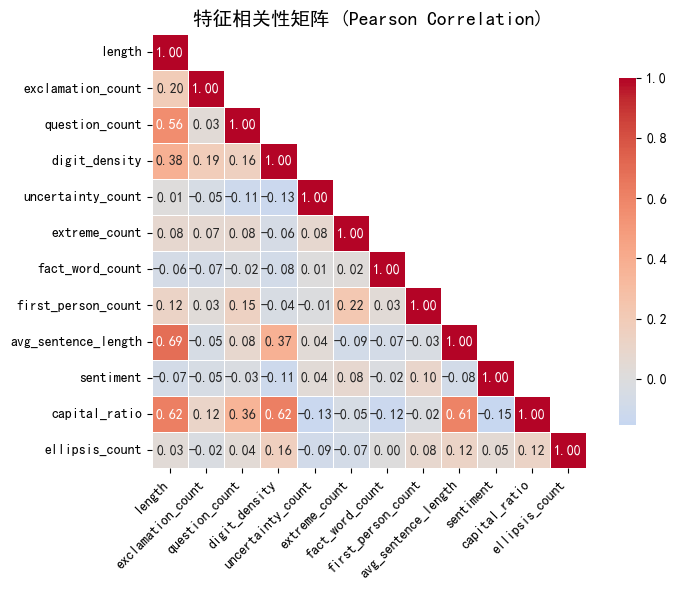


没有发现高度相关的特征对（|r| > 0.7）。


In [6]:
# 特征相关性热力图
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 假设 df_features 已经存在（来自之前的特征提取）
# 如果变量不存在，请先运行数据加载和特征提取代码
try:
    df_features
except NameError:
    print("df_features 未找到，请先运行特征提取代码。")
    # 可选：直接重新加载数据并提取特征（需要你之前的数据加载代码）
    # 这里不自动加载，避免覆盖你的已有变量
    raise

# 计算相关性矩阵（皮尔逊相关系数）
corr_matrix = df_features.corr()

# 设置图形大小
plt.figure(figsize=(8, 6))

# 绘制热力图
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # 只显示下三角，避免重复
sns.heatmap(corr_matrix, 
            mask=mask,
            annot=True,        # 显示数值
            fmt='.2f',         # 保留两位小数
            cmap='coolwarm',   # 红蓝配色
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8})

plt.title('特征相关性矩阵 (Pearson Correlation)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('feature_correlation_heatmap.png', dpi=150)
plt.show()

# 找出高度相关的特征对（|r| > 0.7）
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.7:
            high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], r))

if high_corr_pairs:
    print("\n高度相关的特征对 (|r| > 0.7)：")
    for f1, f2, r in high_corr_pairs:
        print(f"  {f1} — {f2}: {r:.3f}")
else:
    print("\n没有发现高度相关的特征对（|r| > 0.7）。")

In [9]:
# ========== 3. 特征模型训练 ==========
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n[模型训练]")
models = {
    '逻辑回归': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    '随机森林': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
}
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    results[name] = {'model': model, 'accuracy': acc, 'auc': auc, 'y_pred': y_pred, 'y_proba': y_proba}
    print(f"\n{name}: 准确率={acc:.4f}, AUC={auc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['事实', '谣言']))


[模型训练]

逻辑回归: 准确率=0.7952, AUC=0.9021
              precision    recall  f1-score   support

          事实       0.48      0.88      0.62        16
          谣言       0.96      0.78      0.86        67

    accuracy                           0.80        83
   macro avg       0.72      0.83      0.74        83
weighted avg       0.87      0.80      0.81        83


随机森林: 准确率=0.9277, AUC=0.9347
              precision    recall  f1-score   support

          事实       0.86      0.75      0.80        16
          谣言       0.94      0.97      0.96        67

    accuracy                           0.93        83
   macro avg       0.90      0.86      0.88        83
weighted avg       0.93      0.93      0.93        83



In [10]:
# ========== 4. 特征重要性（随机森林） ==========
rf_model = results['随机森林']['model']
importance_df = pd.DataFrame({'feature': df_features.columns, 'importance': rf_model.feature_importances_}).sort_values('importance', ascending=False)
print("\n特征重要性 Top 10:")
print(importance_df.head(10).to_string(index=False))


特征重要性 Top 10:
            feature  importance
             length    0.237889
avg_sentence_length    0.202157
      capital_ratio    0.184692
      digit_density    0.121247
          sentiment    0.084476
  exclamation_count    0.067930
     question_count    0.038490
  uncertainty_count    0.018027
 first_person_count    0.015821
      extreme_count    0.015654


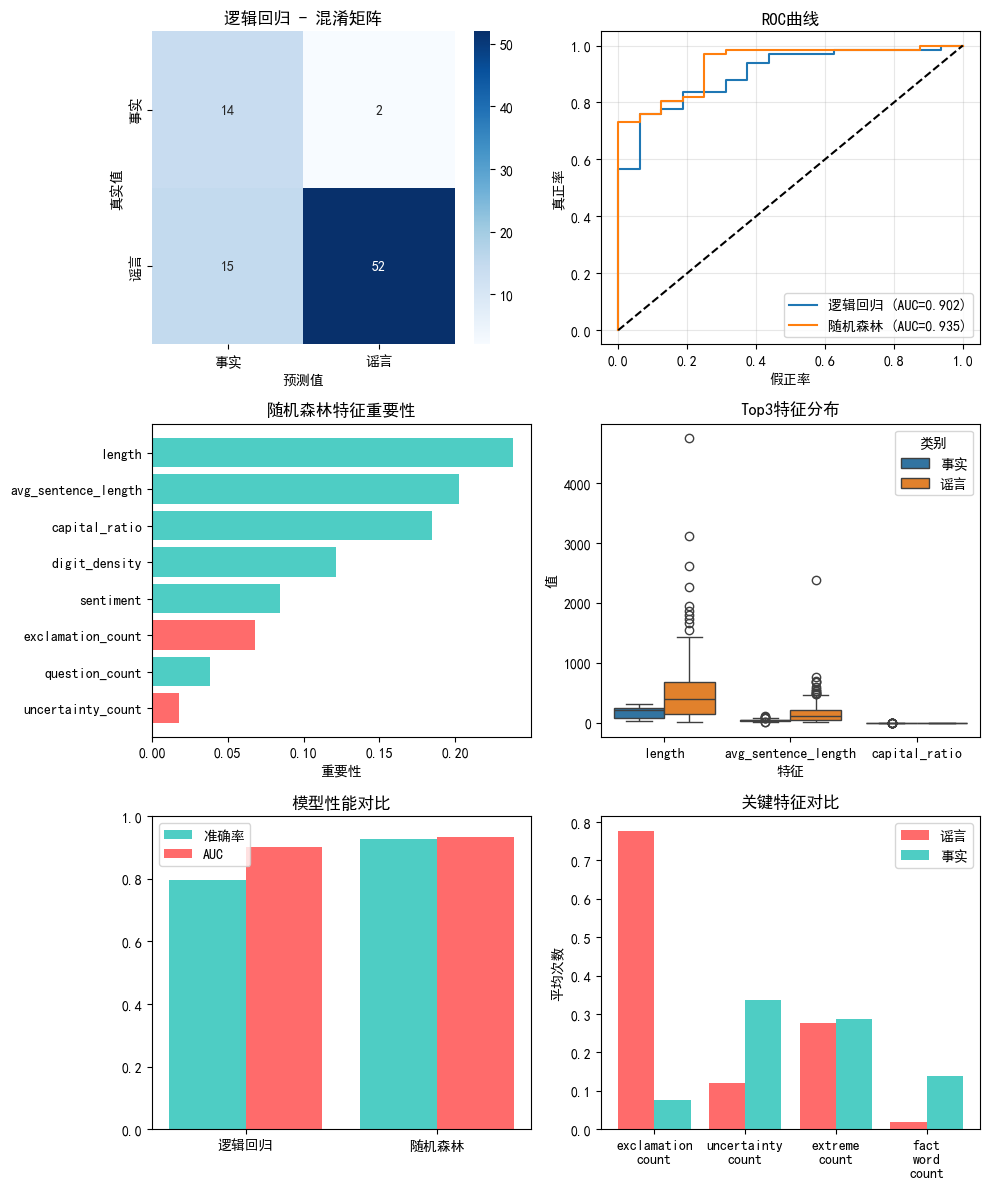

In [11]:
# ========== 8. 可视化 ==========
fig = plt.figure(figsize=(10, 12))
# 混淆矩阵
ax1 = plt.subplot(3, 2, 1)
cm = confusion_matrix(y_test, results['逻辑回归']['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1, xticklabels=['事实','谣言'], yticklabels=['事实','谣言'])
ax1.set_xlabel('预测值')
ax1.set_ylabel('真实值')
ax1.set_title('逻辑回归 - 混淆矩阵')
# ROC曲线
ax2 = plt.subplot(3, 2, 2)
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    ax2.plot(fpr, tpr, label=f"{name} (AUC={res['auc']:.3f})")
ax2.plot([0,1],[0,1],'k--')
ax2.set_xlabel('假正率'); ax2.set_ylabel('真正率'); ax2.legend(); ax2.grid(True,alpha=0.3)
ax2.set_title('ROC曲线')
# 特征重要性
ax3 = plt.subplot(3, 2, 3)
top_feat = importance_df.head(8)
colors = ['#ff6b6b' if f in ['exclamation_count','uncertainty_count','extreme_count'] else '#4ecdc4' for f in top_feat['feature']]
ax3.barh(range(len(top_feat)), top_feat['importance'], color=colors)
ax3.set_yticks(range(len(top_feat))); ax3.set_yticklabels(top_feat['feature'])
ax3.set_xlabel('重要性'); ax3.set_title('随机森林特征重要性'); ax3.invert_yaxis()
# 特征分布箱线图
ax4 = plt.subplot(3, 2, 4)
top3 = importance_df.head(3)['feature'].tolist()
plot_data = []
for feat in top3:
    for label_val in [0,1]:
        vals = df_features[feat][y==label_val]
        for v in vals:
            plot_data.append({'特征':feat,'类别':'事实' if label_val==0 else '谣言','值':v})
sns.boxplot(x='特征', y='值', hue='类别', data=pd.DataFrame(plot_data), ax=ax4)
ax4.set_title('Top3特征分布')
# 模型性能对比
ax5 = plt.subplot(3, 2, 5)
x = np.arange(len(results))
accs = [results[n]['accuracy'] for n in results.keys()]
aucs = [results[n]['auc'] for n in results.keys()]
ax5.bar(x-0.2, accs, 0.4, label='准确率', color='#4ecdc4')
ax5.bar(x+0.2, aucs, 0.4, label='AUC', color='#ff6b6b')
ax5.set_xticks(x); ax5.set_xticklabels(results.keys()); ax5.set_ylim(0,1); ax5.legend(); ax5.set_title('模型性能对比')
# 谣言 vs 事实特征均值
ax6 = plt.subplot(3, 2, 6)
feat_compare = ['exclamation_count','uncertainty_count','extreme_count','fact_word_count']
rumor_means = [df_features[f][y==1].mean() for f in feat_compare]
fact_means = [df_features[f][y==0].mean() for f in feat_compare]
x = np.arange(len(feat_compare))
ax6.bar(x-0.2, rumor_means, 0.4, label='谣言', color='#ff6b6b')
ax6.bar(x+0.2, fact_means, 0.4, label='事实', color='#4ecdc4')
ax6.set_xticks(x); ax6.set_xticklabels([f.replace('_','\n') for f in feat_compare])
ax6.set_ylabel('平均次数'); ax6.set_title('关键特征对比'); ax6.legend()
plt.tight_layout()
plt.savefig('rumor_detection_results.png', dpi=150)
plt.show()

In [12]:
# ========== 9. 典型案例 ==========
print("\n典型案例展示（感叹号最多的谣言 vs 数字密度最高的事实）")
# 找出谣言中感叹号最多的
rumor_indices = [i for i, l in enumerate(y) if l==1]
if rumor_indices:
    exclamations = [df_features.iloc[i]['exclamation_count'] for i in rumor_indices]
    max_exclam_idx = rumor_indices[np.argmax(exclamations)]
    print(f"\n【典型谣言】感叹号={df_features.iloc[max_exclam_idx]['exclamation_count']}")
    print(unique_texts[max_exclam_idx][:200], "...")
fact_indices = [i for i, l in enumerate(y) if l==0]
if fact_indices:
    digit_densities = [df_features.iloc[i]['digit_density'] for i in fact_indices]
    max_digit_idx = fact_indices[np.argmax(digit_densities)]
    print(f"\n【典型事实】数字密度={df_features.iloc[max_digit_idx]['digit_density']:.3f}")
    print(unique_texts[max_digit_idx][:200], "...")

# ========== 10. 交叉验证 ==========
print("\n5折交叉验证:")
X_scaled_all = scaler.fit_transform(X)
for name, model in models.items():
    scores = cross_val_score(model, X_scaled_all, y, cv=5, scoring='accuracy')
    print(f"{name}: 平均准确率={scores.mean():.4f} (+/- {scores.std()*2:.4f})")

print("\n分析完成！")


典型案例展示（感叹号最多的谣言 vs 数字密度最高的事实）

【典型谣言】感叹号=26.0
全国解禁时间表 <br>广东：2月25日结束，已结束！<br>广西：3月5日结束，倒计时5天！<br>海南：2月23日结束，已结束！<br>福建：2月28日结束，已结束！<br>上海：2月27日结束，已结束！<br>江苏：2月27日结束，已结束！<br>浙江：2月23日结束，已结束！<br>安徽：3月3日结束，倒计时3天！<br>北京：3月10日结束，倒计时10天！<br>天津：3月10日结束，倒 ...

【典型事实】数字密度=0.194
如果买不到75%的乙醇，也可以买99.7%的乙醇，稀释到75%后消毒用。 ...

5折交叉验证:
逻辑回归: 平均准确率=0.7491 (+/- 0.4936)
随机森林: 平均准确率=0.7809 (+/- 0.4190)

分析完成！
